In [4]:
from pathlib import Path
import json
import hashlib
import time
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display
from scipy.stats import chi2_contingency, spearmanr

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    ParameterGrid,
    GroupShuffleSplit
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

from lightgbm import LGBMClassifier

from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler


# --------------------------------------------------
# 기본 설정
# --------------------------------------------------

SEED = 20261016

DATA = Path(
    r"nepal_building_damage.csv"
)

DICTIONARY = Path(
    r"nepal_building_damage_dictionary.xlsx"
)

OUT = Path.cwd() / "nepal_results"
OUT.mkdir(parents=True, exist_ok=True)

GEO = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id"
]

NUM = [
    "count_floors_pre_eq",
    "age",
    "area_percentage",
    "height_percentage",
    "count_families"
]

if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"

plt.rcParams["axes.unicode_minus"] = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)


# --------------------------------------------------
# 결과 저장 함수
# --------------------------------------------------

def save_table(table, name):
    table.to_csv(
        OUT / f"{name}.csv",
        index=False,
        encoding="utf-8-sig"
    )


def save_json(value, name):
    text = json.dumps(
        value,
        ensure_ascii=False,
        indent=2,
        default=str
    )

    (OUT / name).write_text(text, encoding="utf-8")


print("데이터 경로:", DATA)
print("결과 저장 폴더:", OUT)

데이터 경로: nepal_building_damage.csv
결과 저장 폴더: c:\t_project_1_1\nepal_results


In [5]:
df = pd.read_csv(DATA).copy()

print("데이터 크기:", df.shape)
display(df.head())

df.info()

quality_table = pd.DataFrame({
    "변수": df.columns,
    "자료형": df.dtypes.astype(str).values,
    "결측수": df.isna().sum().values,
    "고유값수": df.nunique().values
})

display(quality_table)

print("전체 결측값:", df.isna().sum().sum())
print("중복 building_id:", df["building_id"].duplicated().sum())

assert df.shape[1] == 40, "원본 40개 열의 CSV인지 확인하세요."
assert df["building_id"].is_unique, "중복 건물 ID가 있습니다."
assert set(df["damage_grade"].unique()) == {1, 2, 3}
assert df.isna().sum().sum() == 0, "새로운 결측값 처리가 필요합니다."

save_table(quality_table, "data_quality")


# 데이터 사전
if DICTIONARY.exists():
    dictionary = pd.read_excel(
        DICTIONARY,
        sheet_name=0,
        header=7
    )

    display(dictionary)
    save_table(dictionary, "data_dictionary")


# 재현성 확인용 데이터 해시와 패키지 버전
data_hash = hashlib.sha256(DATA.read_bytes()).hexdigest()

package_names = [
    "pandas",
    "numpy",
    "scipy",
    "scikit-learn",
    "lightgbm",
    "imbalanced-learn"
]

versions = {
    name: importlib.metadata.version(name)
    for name in package_names
}

environment = {
    "python": platform.python_version(),
    "packages": versions,
    "data_sha256": data_hash
}

save_json(environment, "environment.json")

print("데이터 SHA256:", data_hash)
display(pd.Series(versions, name="버전"))

데이터 크기: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,...,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,...,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,...,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,...,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,...,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,...,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


<class 'pandas.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   building_id                             260601 non-null  int64
 1   geo_level_1_id                          260601 non-null  int64
 2   geo_level_2_id                          260601 non-null  int64
 3   geo_level_3_id                          260601 non-null  int64
 4   count_floors_pre_eq                     260601 non-null  int64
 5   age                                     260601 non-null  int64
 6   area_percentage                         260601 non-null  int64
 7   height_percentage                       260601 non-null  int64
 8   land_surface_condition                  260601 non-null  str  
 9   foundation_type                         260601 non-null  str  
 10  roof_type                               260601 non-null  str  
 11  ground_floo

,변수,자료형,결측수,고유값수
0,building_id,int64,0,260601
1,geo_level_1_id,int64,0,31
2,geo_level_2_id,int64,0,1414
3,geo_level_3_id,int64,0,11595
4,count_floors_pre_eq,int64,0,9
5,age,int64,0,42
6,area_percentage,int64,0,84
7,height_percentage,int64,0,27
8,land_surface_condition,str,0,3
9,foundation_type,str,0,5


전체 결측값: 0
중복 building_id: 0


,컬럼명,한글명,역할,저장형 / 의미형,정의,단위·값 의미,실제 관측값·범위,고유값 수,결측 수,해석·전처리 주의점
0,building_id,건물 식별자,ID,int64 / 식별자,건물별 고유 무작위 ID,없음,4 ~ 1052934,260601,0,결합 키로만 사용. 모델 입력 제외.
1,geo_level_1_id,대지역 코드,X,int64 / 범주형 정수,가장 넓은 지리 구역,지역 코드,0 ~ 30,31,0,0도 유효 코드. 숫자 크기는 거리·순위를 뜻하지 않음.
2,geo_level_2_id,중지역 코드,X,int64 / 범주형 정수,2단계 지리 구역,지역 코드,0 ~ 1427,1414,0,고유값이 많음. 지역별 미관측 범주 처리 필요.
3,geo_level_3_id,소지역 코드,X,int64 / 범주형 정수,가장 세부적인 지리 구역,지역 코드,0 ~ 12567,11595,0,고유값이 많아 과적합 주의. 지역 일반화 평가 시 그룹 분할 검토.
4,count_floors_pre_eq,지진 전 층수,X,int64 / 수치형 정수,지진 발생 전 건물 층수,층,"1, 2, 3, 4, 5, 6, 7, 8, 9",9,0,높은 층수를 일괄 이상치로 제거하지 않음.
5,age,건물 연령,X,int64 / 수치형 정수,건물의 경과 연수,년,0 ~ 995,42,0,995는 특수값 가능성 검토 대상. 공식 설명만으로 결측 코드라 확정 불가. 0도 자동 결측 처리 금지.
6,area_percentage,정규화 건물 면적,X,int64 / 수치형 정수,건물 바닥 점유면적의 정규화 값,정규화 값,1 ~ 100,84,0,실제 ㎡나 대지 대비 건폐율로 해석 금지. 정규화 기준·분모는 공식 설명에 없음.
7,height_percentage,정규화 건물 높이,X,int64 / 수치형 정수,건물 높이 관련 정규화 값,정규화 값,2 ~ 32,27,0,실제 m로 해석 금지. 정규화 기준·분모는 공식 설명에 없음.
8,land_surface_condition,지표면 상태,X,object / 명목형 문자,건물이 위치한 지면 상태,익명화 코드,"n, o, t",3,0,각 문자의 원래 의미는 비공개. n/o/t에 평지·경사 등을 임의로 대응하지 않음.
9,foundation_type,기초 유형,X,object / 명목형 문자,건물 기초의 종류,익명화 코드,"h, i, r, u, w",5,0,문자별 구체적 재료·공법 매핑 비공개. 원핫 인코딩 등 검토.


데이터 SHA256: 87abd2bc2b05d3e687bd176959967fd38334fff607e6afeb2d20d0d899c13e97


pandas               3.0.6
numpy                2.5.4
scipy               1.18.1
scikit-learn         1.9.1
lightgbm             4.7.0
imbalanced-learn    0.14.2
Name: 버전, dtype: str

In [6]:
X = df.drop(columns=["building_id", "damage_grade"])
y = df["damage_grade"]

idx = np.arange(len(df))


# 전체 → 개발 데이터 80% / test 20%
dev_idx, test_idx = train_test_split(
    idx,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)


# 개발 데이터 80% → train 60% / validation 20%
train_idx, val_idx = train_test_split(
    dev_idx,
    test_size=0.25,
    stratify=y.iloc[dev_idx],
    random_state=SEED
)


# 서로 다른 부분집합인지 확인
assert not set(train_idx) & set(val_idx)
assert not set(dev_idx) & set(test_idx)


# 분석하기 편하게 분리
X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

train = df.iloc[train_idx].copy()


# 건물별 분할 정보 저장
split = pd.DataFrame({
    "building_id": df["building_id"],
    "split": "test"
})

split.loc[train_idx, "split"] = "train"
split.loc[val_idx, "split"] = "validation"

save_table(split, "split_ids")

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

display(split["split"].value_counts())

Train: 156360
Validation: 52120
Test: 52121


split
train         156360
test           52121
validation     52120
Name: count, dtype: int64

,count,ratio,percent
damage_grade,,,
1,15074,0.096406,9.640573
2,88955,0.568911,56.891149
3,52331,0.334683,33.468278


count_floors_pre_eq           age        area_percentage         \
                            mean median   mean median            mean median   
damage_grade                                                                   
1                           1.84    2.0  17.68    5.0            9.69    8.0   
2                           2.13    2.0  27.47   15.0            8.05    7.0   
3                           2.21    2.0  27.95   20.0            7.50    7.0   

             height_percentage        count_families         
                          mean median           mean median  
damage_grade                                                 
1                         5.16    5.0           0.92    1.0  
2                         5.44    5.0           0.98    1.0  
3                         5.52    5.0           1.01    1.0

학습 데이터 age=995 건수: 857
학습 데이터의 입력 속성 중복 행 수: 6427


age
155      1
160      4
170      5
175      3
180      4
185      1
190      2
195      1
200     62
995    857
Name: count, dtype: int64

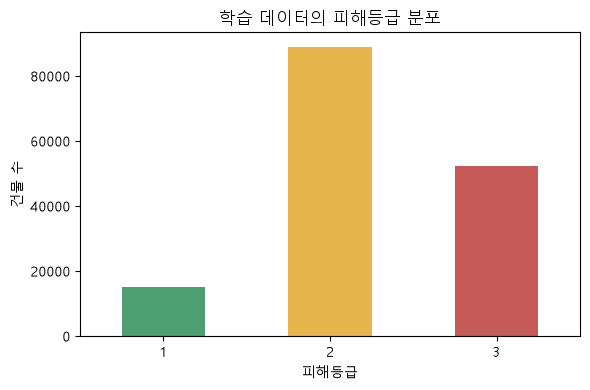

In [7]:
# 등급별 건수와 비율
grade_summary = (
    train["damage_grade"]
    .value_counts()
    .sort_index()
    .rename("count")
    .to_frame()
)

grade_summary["ratio"] = (
    grade_summary["count"] / len(train)
)

grade_summary["percent"] = (
    grade_summary["ratio"] * 100
)

display(grade_summary)

save_table(
    grade_summary.reset_index(),
    "train_grade_distribution"
)


# 등급별 수치형 변수 비교
numeric_by_grade = (
    train.groupby("damage_grade")[NUM]
    .agg(["mean", "median"])
    .round(2)
)

display(numeric_by_grade)

save_table(
    train.groupby("damage_grade")[NUM]
    .mean()
    .reset_index(),
    "train_grade_numeric_means"
)


# 특수값과 속성 중복 확인
print("학습 데이터 age=995 건수:",
      (train["age"] == 995).sum())

print("학습 데이터의 입력 속성 중복 행 수:",
      train[X.columns].duplicated().sum())

display(
    train["age"]
    .value_counts()
    .sort_index()
    .tail(10)
)


# 시각화
fig, ax = plt.subplots(figsize=(6, 4))

grade_summary["count"].plot(
    kind="bar",
    ax=ax,
    color=["#4c9f70", "#e8b44c", "#c65a58"]
)

ax.set_title("학습 데이터의 피해등급 분포")
ax.set_xlabel("피해등급")
ax.set_ylabel("건물 수")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUT / "train_grade_distribution.png",
    dpi=150
)

plt.show()

In [8]:
def grade_table(data, columns):
    """집단별 1·2·3등급 건수와 비율을 계산합니다."""

    table = (
        data.groupby(
            columns + ["damage_grade"],
            observed=True
        )
        .size()
        .unstack(fill_value=0)
    )

    table = table.reindex(
        columns=[1, 2, 3],
        fill_value=0
    )

    table.columns = [
        "count_1",
        "count_2",
        "count_3"
    ]

    table["n"] = table.sum(axis=1)

    overall_ratio = (
        data["damage_grade"]
        .value_counts(normalize=True)
    )

    for grade in [1, 2, 3]:
        table[f"rate_{grade}"] = (
            table[f"count_{grade}"] / table["n"]
        )

        # 표본이 적은 지역을 전체 비율 쪽으로 완만하게 보정
        table[f"smoothed_{grade}"] = (
            table[f"count_{grade}"]
            + 30 * overall_ratio.get(grade, 0)
        ) / (table["n"] + 30)

    return table.reset_index()


def export_rankings(data, prefix):
    """지역 단계별·등급별·순위 기준별 TOP5를 저장합니다."""

    all_top = []

    for geo in GEO:
        table = grade_table(data, [geo])

        save_table(
            table,
            f"{prefix}_{geo}_all_grades"
        )

        for grade in [1, 2, 3]:
            ranking_rules = [
                ("count", f"count_{grade}", 1),
                ("rate_raw", f"rate_{grade}", 1),
                ("rate_n30", f"rate_{grade}", 30),
                ("smoothed", f"smoothed_{grade}", 1)
            ]

            for kind, column, minimum in ranking_rules:
                top = (
                    table[table["n"] >= minimum]
                    .sort_values(
                        [column, "n", geo],
                        ascending=[False, False, True]
                    )
                    .head(5)
                    .copy()
                )

                top = top.rename(columns={geo: "region"})

                top["level"] = geo
                top["grade"] = grade
                top["ranking"] = kind

                all_top.append(top)

    result = pd.concat(all_top, ignore_index=True)

    save_table(result, f"{prefix}_geo_top5")

    return result


top5_train = export_rankings(train, "train")


# 3등급 및 2등급 TOP5 출력
for geo in GEO:
    for grade in [3, 2]:
        print(f"\n[{geo} / {grade}등급]")

        selected = top5_train[
            (top5_train["level"] == geo)
            & (top5_train["grade"] == grade)
            & (
                top5_train["ranking"]
                .isin(["count", "rate_n30"])
            )
        ]

        display(
            selected[
                [
                    "ranking",
                    "region",
                    "n",
                    f"count_{grade}",
                    f"rate_{grade}"
                ]
            ]
        )


[geo_level_1_id / 3등급]


,ranking,region,n,count_3,rate_3
40,count,17,13054,10596,0.811705
41,count,8,11448,5989,0.523148
42,count,10,13298,5301,0.398631
43,count,21,8934,5239,0.586411
44,count,7,11432,4025,0.352082
50,rate_n30,17,13054,10596,0.811705
51,rate_n30,18,1922,1394,0.725286
52,rate_n30,21,8934,5239,0.586411
53,rate_n30,8,11448,5989,0.523148
54,rate_n30,27,7538,3644,0.483417



[geo_level_1_id / 2등급]


,ranking,region,n,count_2,rate_2
20,count,6,14610,9701,0.663997
21,count,26,13626,7597,0.557537
22,count,10,13298,7249,0.545120
23,count,20,10249,7114,0.694116
24,count,7,11432,6798,0.594647
30,rate_n30,29,245,217,0.885714
31,rate_n30,30,1619,1294,0.799259
32,rate_n30,25,3344,2607,0.779605
33,rate_n30,4,8724,6721,0.770403
34,rate_n30,0,2442,1880,0.769861



[geo_level_2_id / 3등급]


...

,ranking,region,n,count_2,rate_2
80,count,39,2444,1137,0.465221
81,count,158,1491,1041,0.698189
82,count,1387,1187,836,0.704297
83,count,181,1265,811,0.641107
84,count,157,1165,729,0.625751
90,rate_n30,1284,33,33,1.000000
91,rate_n30,907,102,100,0.980392
92,rate_n30,725,51,50,0.980392
93,rate_n30,273,42,41,0.976190
94,rate_n30,853,39,38,0.974359



[geo_level_3_id / 3등급]


,ranking,region,n,count_3,rate_3
160,count,8236,192,108,0.562500
161,count,5957,90,87,0.966667
162,count,4391,91,77,0.846154
163,count,7851,72,72,1.000000
164,count,2386,122,71,0.581967
170,rate_n30,7851,72,72,1.000000
171,rate_n30,4221,68,68,1.000000
172,rate_n30,8626,49,49,1.000000
173,rate_n30,9880,47,47,1.000000
174,rate_n30,1408,44,44,1.000000



[geo_level_3_id / 2등급]


,ranking,region,n,count_2,rate_2
140,count,621,317,209,0.659306
141,count,633,397,171,0.430730
142,count,9229,235,156,0.663830
143,count,2005,282,140,0.496454
144,count,2452,209,137,0.655502
150,rate_n30,2822,37,37,1.000000
151,rate_n30,5878,33,33,1.000000
152,rate_n30,11850,30,30,1.000000
153,rate_n30,10810,45,44,0.977778
154,rate_n30,6957,44,43,0.977273


In [9]:
geo3_table = grade_table(
    train,
    ["geo_level_3_id"]
)

overall_grade3_ratio = (
    train["damage_grade"] == 3
).mean()

sensitivity_rows = []

for alpha in [10, 30, 100]:
    temp = geo3_table.copy()

    temp["adjusted_rate3"] = (
        temp["count_3"]
        + alpha * overall_grade3_ratio
    ) / (temp["n"] + alpha)

    top = (
        temp.nlargest(5, "adjusted_rate3")
        .assign(alpha=alpha)
    )

    sensitivity_rows.append(top)

sensitivity = pd.concat(
    sensitivity_rows,
    ignore_index=True
)

display(
    sensitivity[
        [
            "alpha",
            "geo_level_3_id",
            "n",
            "count_3",
            "rate_3",
            "adjusted_rate3"
        ]
    ]
)

save_table(
    sensitivity,
    "train_sparse_smoothing_sensitivity"
)


# 소지역이 여러 상위 지역에 걸쳐 있는지 확인
hierarchy = (
    train.groupby("geo_level_3_id")[GEO[:2]]
    .nunique()
    .max()
)

print("소지역 하나가 속한 상위 지역 수:")
display(hierarchy)

,alpha,geo_level_3_id,n,count_3,rate_3,adjusted_rate3
0,10,7851,72,72,1.000000,0.918864
1,10,4221,68,68,1.000000,0.914703
2,10,5957,90,87,0.966667,0.903468
3,10,1743,70,68,0.971429,0.891835
4,10,8626,49,49,1.000000,0.887234
5,30,5957,90,87,0.966667,0.808671
6,30,7851,72,72,1.000000,0.804318
7,30,4221,68,68,1.000000,0.796331
8,30,1743,70,68,0.971429,0.780405
9,30,1601,63,60,0.952381,0.753123


소지역 하나가 속한 상위 지역 수:


geo_level_1_id    1
geo_level_2_id    1
dtype: int64

In [10]:
MATERIAL = [
    c for c in X.columns
    if c.startswith("has_superstructure_")
]

ARCH = [
    "foundation_type",
    "roof_type",
    "ground_floor_type",
    "other_floor_type",
    "position",
    "plan_configuration",
    "land_surface_condition"
]


def export_elements(data, prefix):
    rows = []

    # --------------------------------------------------
    # 자재 사용 건물의 피해등급 분포
    # --------------------------------------------------
    for material in MATERIAL:
        part = data[data[material] == 1]

        row = {
            "element": material,
            "value": "1",
            "family": "material",
            "n": len(part)
        }

        for grade in [1, 2, 3]:
            count = int(
                (part["damage_grade"] == grade).sum()
            )

            row[f"count_{grade}"] = count
            row[f"rate_{grade}"] = (
                count / max(len(part), 1)
            )

        rows.append(row)

    # --------------------------------------------------
    # 기초·지붕·바닥 등 건축 유형
    # --------------------------------------------------
    for column in ARCH:
        table = grade_table(data, [column])

        table = table.rename(
            columns={column: "value"}
        )

        table["element"] = column
        table["family"] = "architecture"

        rows.extend(table.to_dict("records"))

    elements = pd.DataFrame(rows)

    save_table(
        elements,
        f"{prefix}_element_all_grades"
    )

    # --------------------------------------------------
    # 건수 TOP5 / 비율 TOP5
    # --------------------------------------------------
    top_rows = []

    for family in ["material", "architecture"]:
        for grade in [1, 2, 3]:
            for kind, minimum in [
                ("count", 1),
                ("rate", 30)
            ]:
                top = (
                    elements[
                        (elements["family"] == family)
                        & (elements["n"] >= minimum)
                    ]
                    .nlargest(5, f"{kind}_{grade}")
                    .copy()
                )

                top["grade"] = grade
                top["ranking"] = kind

                top_rows.append(top)

    element_top5 = pd.concat(
        top_rows,
        ignore_index=True
    )

    save_table(
        element_top5,
        f"{prefix}_element_top5"
    )

    # --------------------------------------------------
    # 지역 × 자재
    # --------------------------------------------------
    combination_rows = []

    for geo in GEO:
        for material in MATERIAL:
            part = data[data[material] == 1]

            table = grade_table(part, [geo])

            table = table.rename(
                columns={geo: "region"}
            )

            table["level"] = geo
            table["material"] = material

            combination_rows.append(table)

    combinations = pd.concat(
        combination_rows,
        ignore_index=True
    )

    save_table(
        combinations,
        f"{prefix}_geo_material_all_grades"
    )

    combination_top5 = (
        combinations[combinations["n"] >= 30]
        .sort_values("rate_3", ascending=False)
        .groupby("level", sort=False)
        .head(5)
    )

    save_table(
        combination_top5,
        f"{prefix}_geo_material_top5_rate3"
    )

    return elements


elements = export_elements(train, "train")


# 건축 요소별 TOP5 보기
element_top5 = pd.read_csv(
    OUT / "train_element_top5.csv"
)

for family in ["material", "architecture"]:
    for grade in [3, 2]:
        print(f"\n[{family} / {grade}등급]")

        display(
            element_top5[
                (element_top5["family"] == family)
                & (element_top5["grade"] == grade)
            ][
                [
                    "ranking",
                    "element",
                    "value",
                    "n",
                    f"count_{grade}",
                    f"rate_{grade}"
                ]
            ]
        )


# 지역 × 자재의 3등급 비율 TOP5
print("\n[지역 × 자재 / 3등급 비율 TOP5]")

display(
    pd.read_csv(
        OUT / "train_geo_material_top5_rate3.csv"
    )
)


[material / 3등급]


,ranking,element,value,n,count_3,rate_3
20,count,has_superstructure_mud_mortar_stone,1,118975,45496,0.382400
21,count,has_superstructure_timber,1,39835,11159,0.280131
22,count,has_superstructure_adobe_mud,1,14035,5194,0.370075
23,count,has_superstructure_mud_mortar_brick,1,10683,3260,0.305158
24,count,has_superstructure_bamboo,1,13163,3142,0.238699
25,rate,has_superstructure_stone_flag,1,5303,2480,0.467660
26,rate,has_superstructure_mud_mortar_stone,1,118975,45496,0.382400
27,rate,has_superstructure_adobe_mud,1,14035,5194,0.370075
28,rate,has_superstructure_mud_mortar_brick,1,10683,3260,0.305158
29,rate,has_superstructure_timber,1,39835,11159,0.280131



[material / 2등급]


,ranking,element,value,n,count_2,rate_2
10,count,has_superstructure_mud_mortar_stone,1,118975,68258,0.573717
11,count,has_superstructure_timber,1,39835,24059,0.603966
12,count,has_superstructure_adobe_mud,1,14035,8493,0.605130
13,count,has_superstructure_bamboo,1,13163,8354,0.634658
14,count,has_superstructure_mud_mortar_brick,1,10683,7050,0.659927
15,rate,has_superstructure_cement_mortar_stone,1,2846,1973,0.693254
16,rate,has_superstructure_mud_mortar_brick,1,10683,7050,0.659927
17,rate,has_superstructure_bamboo,1,13163,8354,0.634658
18,rate,has_superstructure_adobe_mud,1,14035,8493,0.605130
19,rate,has_superstructure_timber,1,39835,24059,0.603966



[architecture / 3등급]


,ranking,element,value,n,count_3,rate_3
50,count,plan_configuration,d,150075,50536,0.336738
51,count,foundation_type,r,131508,49823,0.378859
52,count,ground_floor_type,f,125665,46372,0.369013
53,count,land_surface_condition,t,130179,43678,0.335523
54,count,position,s,121240,39599,0.326617
55,rate,plan_configuration,q,3437,1419,0.412860
56,rate,position,t,25646,10132,0.395071
57,rate,roof_type,q,36836,14101,0.382805
58,rate,foundation_type,r,131508,49823,0.378859
59,rate,other_floor_type,x,26109,9776,0.374430



[architecture / 2등급]


,ranking,element,value,n,count_2,rate_2
40,count,plan_configuration,d,150075,85509,0.569775
41,count,foundation_type,r,131508,75248,0.572193
42,count,land_surface_condition,t,130179,73345,0.563417
43,count,ground_floor_type,f,125665,71759,0.571034
44,count,position,s,121240,69696,0.574860
45,rate,plan_configuration,m,33,24,0.727273
46,rate,position,o,1410,973,0.690071
47,rate,ground_floor_type,m,332,225,0.677711
48,rate,plan_configuration,o,95,64,0.673684
49,rate,plan_configuration,s,193,129,0.668394



[지역 × 자재 / 3등급 비율 TOP5]


,region,count_1,count_2,count_3,n,rate_1,smoothed_1,rate_2,smoothed_2,rate_3,smoothed_3,level,material
0,10592,0,0,31,31,0.000000,0.062283,0.000000,0.312127,1.000000,0.625590,geo_level_3_id,has_superstructure_bamboo
1,1183,0,0,96,96,0.000000,0.027596,0.000000,0.143802,1.000000,0.828603,geo_level_2_id,has_superstructure_timber
2,817,0,0,110,110,0.000000,0.024836,0.000000,0.129421,1.000000,0.845742,geo_level_2_id,has_superstructure_timber
3,3022,0,0,30,30,0.000000,0.012398,0.000000,0.302565,1.000000,0.685037,geo_level_3_id,has_superstructure_adobe_mud
4,123,0,0,64,64,0.000000,0.109622,0.000000,0.169171,1.000000,0.721208,geo_level_2_id,has_superstructure_rc_non_engineered
5,399,0,0,56,56,0.000000,0.040431,0.000000,0.210686,1.000000,0.748883,geo_level_2_id,has_superstructure_timber
6,977,0,0,51,51,0.000000,0.127215,0.000000,0.196321,1.000000,0.676463,geo_level_2_id,has_superstructure_rc_non_engineered
7,4221,0,0,68,68,0.000000,0.038768,0.000000,0.194283,1.000000,0.766949,geo_level_3_id,has_superstructure_bamboo
8,482,0,0,41,41,0.000000,0.018542,0.000000,0.242416,1.000000,0.739042,geo_level_3_id,has_superstructure_mud_mortar_stone
9,5957,0,0,33,33,0.000000,0.060306,0.000000,0.302218,1.000000,0.637476,geo_level_3_id,has_superstructure_bamboo


Pearson 상관계수


,count_floors_pre_eq,age,area_percentage,height_percentage,count_families
count_floors_pre_eq,1.000,0.083,0.103,0.772,0.084
age,0.083,1.000,-0.005,0.058,0.010
area_percentage,0.103,-0.005,1.000,0.197,0.091
height_percentage,0.772,0.058,0.197,1.000,0.064
count_families,0.084,0.010,0.091,0.064,1.000


Spearman 상관계수


,count_floors_pre_eq,age,area_percentage,height_percentage,count_families
count_floors_pre_eq,1.000,0.254,0.125,0.756,0.076
age,0.254,1.000,-0.018,0.194,0.046
area_percentage,0.125,-0.018,1.000,0.208,0.079
height_percentage,0.756,0.194,0.208,1.000,0.061
count_families,0.076,0.046,0.079,0.061,1.000


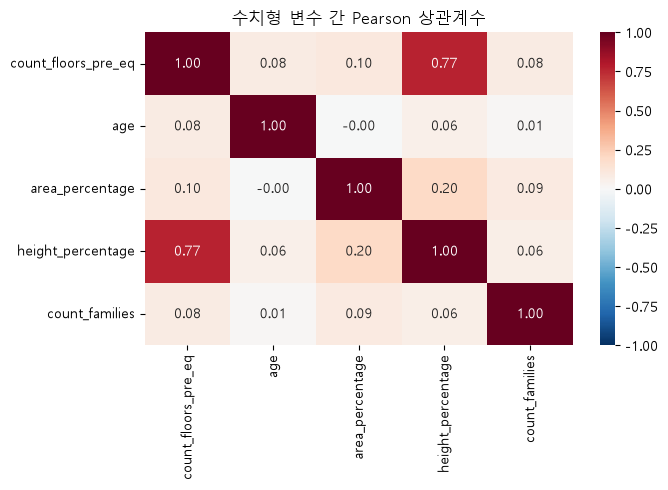

,feature,spearman,p_value
1,age,0.173320,0.000000e+00
0,count_floors_pre_eq,0.140118,0.000000e+00
3,height_percentage,0.080120,5.570623e-221
4,count_families,0.060235,1.286967e-125
2,area_percentage,-0.100905,0.000000e+00


In [11]:
# 수치형 변수끼리의 Pearson 상관
pearson_corr = train[NUM].corr()

# 수치형 변수끼리의 Spearman 상관
spearman_corr = train[NUM].corr(
    method="spearman"
)

print("Pearson 상관계수")
display(pearson_corr.round(3))

print("Spearman 상관계수")
display(spearman_corr.round(3))

save_table(
    pearson_corr.reset_index(),
    "train_numeric_pearson"
)

save_table(
    spearman_corr.reset_index(),
    "train_numeric_spearman"
)


plt.figure(figsize=(7, 5))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("수치형 변수 간 Pearson 상관계수")
plt.tight_layout()
plt.show()


# 피해등급과의 Spearman 상관
target_corr_rows = []

for column in NUM:
    correlation, p_value = spearmanr(
        train[column],
        train["damage_grade"]
    )

    target_corr_rows.append({
        "feature": column,
        "spearman": correlation,
        "p_value": p_value
    })

target_corr = pd.DataFrame(target_corr_rows)

display(
    target_corr.sort_values(
        "spearman",
        ascending=False
    )
)

save_table(
    target_corr,
    "train_target_spearman"
)

In [12]:
def association(a, b):
    table = pd.crosstab(a, b)

    if min(table.shape) < 2:
        return {
            "p_value": np.nan,
            "cramers_v_corrected": np.nan
        }

    chi2, p_value, dof, expected = (
        chi2_contingency(
            table,
            correction=False
        )
    )

    n = table.to_numpy().sum()
    r, k = table.shape

    # 편향을 보정한 Cramer's V
    phi = max(
        0,
        chi2 / n
        - (k - 1) * (r - 1) / (n - 1)
    )

    denominator = min(
        k - 1 - (k - 1) ** 2 / (n - 1),
        r - 1 - (r - 1) ** 2 / (n - 1)
    )

    if denominator > 0:
        corrected_v = np.sqrt(
            phi / denominator
        )
    else:
        corrected_v = np.nan

    return {
        "chi2": chi2,
        "p_value": p_value,
        "cramers_v_corrected": corrected_v,
        "expected_lt5_ratio": float(
            (expected < 5).mean()
        ),
        "expected_min": float(expected.min()),
        "approximation_ok": bool(
            expected.min() >= 1
            and (expected < 5).mean() <= 0.2
        )
    }


cat_cols = GEO + [
    c for c in X.columns
    if c not in GEO
    and (
        c.startswith("has_")
        or not pd.api.types.is_numeric_dtype(X[c])
    )
]


association_rows = []

# 범주형 변수 × 피해등급
for column in cat_cols:
    result = association(
        train[column],
        train["damage_grade"]
    )

    association_rows.append({
        "feature_a": column,
        "feature_b": "damage_grade",
        **result
    })


# 지역 × 건축 재료
for geo in GEO:
    for material in MATERIAL:
        result = association(
            train[geo],
            train[material]
        )

        association_rows.append({
            "feature_a": geo,
            "feature_b": material,
            **result
        })

association_table = pd.DataFrame(
    association_rows
)


# Benjamini-Hochberg FDR 보정
sorted_p = (
    association_table["p_value"]
    .dropna()
    .sort_values()
)

number_of_tests = len(sorted_p)
rank = np.arange(1, number_of_tests + 1)

adjusted = (
    sorted_p.to_numpy()
    * number_of_tests
    / rank
)

adjusted = np.minimum.accumulate(
    adjusted[::-1]
)[::-1]

association_table.loc[
    sorted_p.index,
    "p_fdr_bh"
] = np.minimum(adjusted, 1)


save_table(
    association_table,
    "train_chi_square"
)

display(
    association_table[
        association_table["feature_b"]
        == "damage_grade"
    ]
    .sort_values(
        "cramers_v_corrected",
        ascending=False
    )
)

,feature_a,feature_b,chi2,p_value,cramers_v_corrected,expected_lt5_ratio,expected_min,approximation_ok,p_fdr_bh
2,geo_level_3_id,damage_grade,115067.919976,0.000000e+00,0.545508,0.699194,0.096406,False,0.000000e+00
1,geo_level_2_id,damage_grade,81768.062329,0.000000e+00,0.502542,0.268671,0.096406,False,0.000000e+00
0,geo_level_1_id,damage_grade,44128.674535,0.000000e+00,0.375396,0.000000,16.196163,True,0.000000e+00
11,has_superstructure_mud_mortar_stone,damage_grade,17644.265999,0.000000e+00,0.335904,0.000000,3604.128230,True,0.000000e+00
4,foundation_type,damage_grade,29059.042670,0.000000e+00,0.304794,0.000000,84.740637,True,0.000000e+00
15,has_superstructure_cement_mortar_brick,damage_grade,12276.001618,0.000000e+00,0.280176,0.000000,1138.551676,True,0.000000e+00
6,ground_floor_type,damage_grade,21491.157619,0.000000e+00,0.262104,0.000000,32.006702,True,0.000000e+00
7,other_floor_type,damage_grade,18751.250191,0.000000e+00,0.244833,0.000000,703.569020,True,0.000000e+00
5,roof_type,damage_grade,17821.848926,0.000000e+00,0.238700,0.000000,941.209146,True,0.000000e+00
19,has_superstructure_rc_engineered,damage_grade,8667.129422,0.000000e+00,0.235411,0.000000,243.713686,True,0.000000e+00


In [13]:
def add_features(X, mode):
    """
    건물 한 행의 입력 정보만으로 만들 수 있는 파생변수.
    정답 y는 받지 않습니다.
    """

    result = X.copy()

    if mode == "raw":
        return result

    material_cols = [
        c for c in result.columns
        if c.startswith("has_superstructure_")
    ]

    result["material_count"] = (
        result[material_cols].sum(axis=1)
    )

    result["height_per_floor"] = (
        result["height_percentage"]
        / result["count_floors_pre_eq"].clip(lower=1)
    )

    result["height_area_ratio"] = (
        result["height_percentage"]
        / result["area_percentage"].clip(lower=1)
    )

    # 원래 age 값은 유지하고 특수값 여부만 추가
    result["age_is_995"] = (
        result["age"] == 995
    ).astype(int)

    result["foundation_roof"] = (
        result["foundation_type"].astype(str)
        + "|"
        + result["roof_type"].astype(str)
    )

    result["geo1_mudstone"] = (
        result["geo_level_1_id"].astype(str)
        + "|"
        + result[
            "has_superstructure_mud_mortar_stone"
        ].astype(str)
    )

    result["geo2_foundation"] = (
        result["geo_level_2_id"].astype(str)
        + "|"
        + result["foundation_type"].astype(str)
    )

    return result


def fit_features(X, mode):
    """
    학습 데이터에서 전처리 규칙을 배웁니다.
    변환된 데이터와 저장할 규칙을 반환합니다.
    """

    result = add_features(X, mode)

    state = {
        "mode": mode,
        "counts": {},
        "material_means": {},
        "categories": {}
    }

    if mode == "geo":
        material = (
            "has_superstructure_mud_mortar_stone"
        )

        state["global_material"] = float(
            X[material].mean()
        )

        for geo in GEO:
            counts = X[geo].value_counts()

            material_means = (
                X.groupby(geo)[material].mean()
            )

            state["counts"][geo] = counts
            state["material_means"][geo] = (
                material_means
            )

            result[f"{geo}_count"] = (
                X[geo].map(counts).astype(float)
            )

            result[f"{geo}_mud_rate"] = (
                X[geo].map(material_means)
            )

    categorical = [
        c for c in result.columns
        if c in GEO
        or not pd.api.types.is_numeric_dtype(
            result[c]
        )
    ]

    for column in categorical:
        categories = sorted(
            result[column]
            .dropna()
            .unique()
            .tolist()
        )

        state["categories"][column] = categories

        result[column] = pd.Categorical(
            result[column],
            categories=categories
        )

    state["columns"] = result.columns.tolist()

    return result, state


def transform_features(X, state):
    """
    학습 때 저장한 규칙으로 validation/test/새 데이터를 변환합니다.
    """

    result = add_features(
        X,
        state["mode"]
    )

    for geo, counts in state["counts"].items():
        # 처음 보는 지역의 학습 건물 수는 0
        result[f"{geo}_count"] = (
            X[geo]
            .map(counts)
            .fillna(0)
            .astype(float)
        )

        # 처음 보는 지역의 재료 사용률은 학습 전체 평균
        result[f"{geo}_mud_rate"] = (
            X[geo]
            .map(state["material_means"][geo])
            .fillna(state["global_material"])
        )

    for column, categories in (
        state["categories"].items()
    ):
        # 학습에 없던 범주는 NaN으로 처리
        result[column] = pd.Categorical(
            result[column],
            categories=categories
        )

    return result[state["columns"]]


# 파생변수 개수 확인
for mode in ["raw", "basic", "geo"]:
    sample, state = fit_features(
        X_train,
        mode
    )

    print(mode, "입력 변수 수:", sample.shape[1])

raw 입력 변수 수: 38
basic 입력 변수 수: 45
geo 입력 변수 수: 51


In [14]:
def make_model(kind, X, method="none", params=None):
    params = {} if params is None else params.copy()

    class_weight = None

    if method == "balanced":
        class_weight = "balanced"

    elif method == "grade3":
        class_weight = {
            1: 1.5,
            2: 1.0,
            3: 1.2
        }

    # --------------------------------------------------
    # LightGBM
    # pandas category를 범주형으로 사용
    # --------------------------------------------------
    if kind == "lgbm":
        settings = {
            "n_estimators": 100,
            "random_state": SEED,
            "n_jobs": 4,
            "verbosity": -1,
            "deterministic": True,
            "force_col_wise": True,
            "class_weight": class_weight
        }

        settings.update(params)

        return LGBMClassifier(**settings)

    # --------------------------------------------------
    # 최빈 등급만 예측하는 기준 모델
    # --------------------------------------------------
    if kind == "dummy":
        return DummyClassifier(
            strategy="most_frequent"
        )

    # --------------------------------------------------
    # Logistic / Random Forest용 전처리
    # --------------------------------------------------
    cat = [
        c for c in X.columns
        if isinstance(
            X[c].dtype,
            pd.CategoricalDtype
        )
    ]

    num = [
        c for c in X.columns
        if c not in cat
    ]

    numeric_pipeline = Pipeline([
        (
            "fill",
            SimpleImputer(strategy="median")
        ),
        (
            "scale",
            StandardScaler()
        )
    ])

    preprocess = ColumnTransformer([
        (
            "num",
            numeric_pipeline,
            num
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                dtype=np.float32
            ),
            cat
        )
    ])

    if kind == "logistic":
        model = LogisticRegression(
            solver="saga",
            max_iter=600,
            tol=0.001,
            random_state=SEED,
            class_weight=class_weight
        )

    elif kind == "forest":
        model = RandomForestClassifier(
            n_estimators=100,
            max_depth=22,
            min_samples_leaf=3,
            n_jobs=4,
            random_state=SEED,
            class_weight=class_weight
        )

    else:
        raise ValueError(
            f"알 수 없는 모델: {kind}"
        )

    return Pipeline([
        ("preprocess", preprocess),
        ("model", model)
    ])


def train_model(X, y, config):
    # 학습 데이터로만 전처리 규칙 생성
    train_x, state = fit_features(
        X,
        config["features"]
    )

    method = config["method"]

    model = make_model(
        config["kind"],
        train_x,
        method,
        config.get("params")
    )

    weights = None

    # --------------------------------------------------
    # 희소지역 가중치
    # 학습 소지역 건물 수가 적을수록 가중치를 높임
    # 과도한 가중을 막기 위해 1~3으로 제한
    # --------------------------------------------------
    if method == "rare_region":
        counts = (
            X["geo_level_3_id"]
            .value_counts()
        )

        row_counts = (
            X["geo_level_3_id"].map(counts)
        )

        weights = (
            np.sqrt(30 / row_counts)
            .clip(1, 3)
            .to_numpy()
        )

        weights = weights / weights.mean()

    # --------------------------------------------------
    # 샘플링은 학습 데이터에만 적용
    # --------------------------------------------------
    sampling_methods = [
        "under_partial",
        "under_full",
        "over_full"
    ]

    if method in sampling_methods:
        if method == "under_partial":
            cap = min(
                int((y == 2).sum()),
                int((y == 3).sum())
            )

            sampler = RandomUnderSampler(
                sampling_strategy={2: cap},
                random_state=SEED
            )

        elif method == "under_full":
            sampler = RandomUnderSampler(
                random_state=SEED
            )

        else:
            sampler = RandomOverSampler(
                random_state=SEED
            )

        train_x, y = sampler.fit_resample(
            train_x,
            y
        )

    # --------------------------------------------------
    # 모델 학습
    # --------------------------------------------------
    if weights is None:
        model.fit(train_x, y)

    else:
        model.fit(
            train_x,
            y,
            sample_weight=weights
        )

    return {
        "model": model,
        "state": state,
        "config": config,
        "train_n": len(y)
    }


def predict_model(bundle, X):
    transformed = transform_features(
        X,
        bundle["state"]
    )

    return bundle["model"].predict(transformed)


def metrics(y_true, y_pred):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[1, 2, 3]
    )

    report = classification_report(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        output_dict=True,
        zero_division=0
    )

    result = {
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "micro_f1": f1_score(
            y_true,
            y_pred,
            average="micro"
        ),
        "weighted_f1": f1_score(
            y_true,
            y_pred,
            average="weighted"
        ),
        "accuracy": accuracy_score(
            y_true,
            y_pred
        )
    }

    for grade in [1, 2, 3]:
        for metric_name in [
            "precision",
            "recall",
            "f1-score"
        ]:
            result[
                f"{metric_name}_{grade}"
            ] = report[str(grade)][metric_name]

    # 실제 3등급 중 잘못 예측한 비율
    n_grade3 = max(cm[2].sum(), 1)

    result["error_3_to_2"] = (
        cm[2, 1] / n_grade3
    )

    result["error_3_to_1"] = (
        cm[2, 0] / n_grade3
    )

    return result

In [15]:
configs = [
    {
        "name": "Dummy",
        "kind": "dummy",
        "features": "raw",
        "method": "none"
    },
    {
        "name": "Logistic",
        "kind": "logistic",
        "features": "raw",
        "method": "none"
    },
    {
        "name": "RandomForest",
        "kind": "forest",
        "features": "raw",
        "method": "none"
    }
]


# LightGBM의 피처 구성 비교
for mode in ["raw", "basic", "geo"]:
    configs.append({
        "name": f"LGBM_{mode}",
        "kind": "lgbm",
        "features": mode,
        "method": "none"
    })


# LightGBM의 불균형·희소지역 처리 비교
methods = [
    "balanced",
    "grade3",
    "under_partial",
    "under_full",
    "over_full",
    "rare_region"
]

for method in methods:
    configs.append({
        "name": f"LGBM_{method}",
        "kind": "lgbm",
        "features": "raw",
        "method": method
    })


validation_rows = []

for config in configs:
    started = time.perf_counter()

    bundle = train_model(
        X_train,
        y_train,
        config
    )

    val_pred = predict_model(
        bundle,
        X_val
    )

    result = {
        "name": config["name"],
        "train_n": bundle["train_n"],
        "features_n": len(
            bundle["state"]["columns"]
        ),
        **metrics(y_val, val_pred),
        "seconds": (
            time.perf_counter() - started
        )
    }

    validation_rows.append(result)

    save_table(
        pd.DataFrame(validation_rows),
        "validation_comparison"
    )

    print(
        config["name"],
        "Macro F1:",
        round(result["macro_f1"], 5),
        flush=True
    )


validation = (
    pd.DataFrame(validation_rows)
    .sort_values(
        "macro_f1",
        ascending=False
    )
)

display(
    validation[
        [
            "name",
            "train_n",
            "features_n",
            "macro_f1",
            "micro_f1",
            "recall_1",
            "recall_2",
            "recall_3",
            "error_3_to_2",
            "seconds"
        ]
    ]
)

Dummy Macro F1: 0.24175


C:\Users\jhj31\AppData\Local\Temp\ipykernel_37824\589779393.py:161: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  result[column] = pd.Categorical(


Logistic Macro F1: 0.66383


C:\Users\jhj31\AppData\Local\Temp\ipykernel_37824\589779393.py:161: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  result[column] = pd.Categorical(
C:\Users\jhj31\AppData\Local\Temp\ipykernel_37824\589779393.py:161: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  result[column] = pd.Categorical(


RandomForest Macro F1: 0.36231


...

C:\Users\jhj31\AppData\Local\Temp\ipykernel_37824\589779393.py:161: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  result[column] = pd.Categorical(


LGBM_over_full Macro F1: 0.68167


C:\Users\jhj31\AppData\Local\Temp\ipykernel_37824\589779393.py:161: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  result[column] = pd.Categorical(


LGBM_rare_region Macro F1: 0.69806


,name,train_n,features_n,macro_f1,micro_f1,recall_1,recall_2,recall_3,error_3_to_2,seconds
7,LGBM_grade3,156360,38,0.705205,0.741942,0.634030,0.800722,0.673107,0.315829,4.542043
5,LGBM_geo,156360,51,0.699208,0.745894,0.555025,0.839741,0.641346,0.350456,5.599477
8,LGBM_under_partial,119736,38,0.699125,0.726516,0.665672,0.727034,0.743163,0.244625,3.589720
3,LGBM_raw,156360,38,0.698578,0.745894,0.553234,0.841157,0.639454,0.353322,4.203820
4,LGBM_basic,156360,45,0.698535,0.745530,0.553433,0.839876,0.640486,0.351258,4.163490
11,LGBM_rare_region,156360,38,0.698056,0.745261,0.552637,0.839134,0.641174,0.350914,4.619548
10,LGBM_over_full,266865,38,0.681671,0.707157,0.812935,0.674524,0.732156,0.239695,6.033274
6,LGBM_balanced,156360,38,0.679520,0.704777,0.827264,0.665958,0.735481,0.234191,4.446023
1,Logistic,156360,38,0.663829,0.732176,0.431244,0.855254,0.609643,0.385943,31.485368
9,LGBM_under_full,45222,38,0.654982,0.677168,0.849751,0.623263,0.719085,0.243880,1.600485


In [16]:
# 모델 이름으로 설정을 찾기 위한 딕셔너리
by_name = {
    config["name"]: config
    for config in configs
}


# validation 상위 3개 구성
cv_configs = [
    by_name[name].copy()
    for name in validation["name"].head(3)
]


# validation에서 가장 좋은 LightGBM 구성
best_lgbm_name = next(
    name
    for name in validation["name"]
    if by_name[name]["kind"] == "lgbm"
)

base_tuning = by_name[best_lgbm_name]

print("튜닝의 출발 구성:", best_lgbm_name)


# --------------------------------------------------
# 사전에 정한 6개 튜닝 후보
# --------------------------------------------------
tuning_grid = list(
    ParameterGrid({
        "n_estimators": [400, 900, 1500],
        "num_leaves": [31, 63]
    })
)

for number, params in enumerate(
    tuning_grid,
    start=1
):
    params.update({
        "learning_rate": 0.05,
        "min_child_samples": 30,
        "reg_lambda": 1.0
    })

    cv_configs.append({
        **base_tuning,
        "name": f"LGBM_tuned_{number}",
        "params": params
    })

save_json(
    cv_configs,
    "candidate_configs.json"
)


# --------------------------------------------------
# 모든 후보가 같은 fold를 사용
# --------------------------------------------------
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

folds = list(
    cv.split(
        X.iloc[dev_idx],
        y.iloc[dev_idx]
    )
)


# --------------------------------------------------
# CV 실행
# --------------------------------------------------
cv_rows = []

for config in cv_configs:
    for fold_number, (a, b) in enumerate(
        folds,
        start=1
    ):
        # 개발 데이터 내부 위치 → 원본 데이터 위치
        fold_train_idx = dev_idx[a]
        fold_val_idx = dev_idx[b]

        bundle = train_model(
            X.iloc[fold_train_idx],
            y.iloc[fold_train_idx],
            config
        )

        fold_pred = predict_model(
            bundle,
            X.iloc[fold_val_idx]
        )

        result = {
            "name": config["name"],
            "fold": fold_number,
            **metrics(
                y.iloc[fold_val_idx],
                fold_pred
            )
        }

        cv_rows.append(result)

        save_table(
            pd.DataFrame(cv_rows),
            "cv_folds"
        )

        print(
            config["name"],
            "fold:",
            fold_number,
            "Macro F1:",
            round(result["macro_f1"], 5),
            flush=True
        )


# --------------------------------------------------
# CV 평균·표준편차
# --------------------------------------------------
cv_table = pd.DataFrame(cv_rows)

cv_summary = (
    cv_table.groupby("name")["macro_f1"]
    .agg(["mean", "std"])
    .reset_index()
    .sort_values(
        ["mean", "std", "name"],
        ascending=[False, True, True]
    )
)

display(cv_summary)

save_table(
    cv_summary,
    "cv_summary"
)


# 최고 평균 점수의 구성 선택
winner_name = cv_summary.iloc[0]["name"]

winner = next(
    config
    for config in cv_configs
    if config["name"] == winner_name
)

print("최종 선택 구성:")
print(
    json.dumps(
        winner,
        ensure_ascii=False,
        indent=2
    )
)

save_json(
    winner,
    "selected_config_before_test.json"
)

튜닝의 출발 구성: LGBM_grade3


C:\Users\jhj31\AppData\Local\Temp\ipykernel_37824\589779393.py:161: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  result[column] = pd.Categorical(


LGBM_grade3 fold: 1 Macro F1: 0.69861


C:\Users\jhj31\AppData\Local\Temp\ipykernel_37824\589779393.py:161: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  result[column] = pd.Categorical(


LGBM_grade3 fold: 2 Macro F1: 0.70455


...

LGBM_tuned_6 fold: 2 Macro F1: 0.69396


C:\Users\jhj31\AppData\Local\Temp\ipykernel_37824\589779393.py:161: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  result[column] = pd.Categorical(


LGBM_tuned_6 fold: 3 Macro F1: 0.69054


,name,mean,std
2,LGBM_tuned_1,0.701432,0.001549
1,LGBM_grade3,0.701267,0.003020
4,LGBM_tuned_3,0.699610,0.000819
3,LGBM_tuned_2,0.699159,0.001753
6,LGBM_tuned_5,0.697859,0.000835
5,LGBM_tuned_4,0.695757,0.001382
8,LGBM_under_partial,0.695626,0.001327
0,LGBM_geo,0.695551,0.001342
7,LGBM_tuned_6,0.692289,0.001713


최종 선택 구성:
{
  "name": "LGBM_tuned_1",
  "kind": "lgbm",
  "features": "raw",
  "method": "grade3",
  "params": {
    "n_estimators": 400,
    "num_leaves": 31,
    "learning_rate": 0.05,
    "min_child_samples": 30,
    "reg_lambda": 1.0
  }
}


In [17]:
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

a, b = next(
    group_split.split(
        X.iloc[dev_idx],
        y.iloc[dev_idx],
        groups=(
            X.iloc[dev_idx]["geo_level_2_id"]
        )
    )
)

group_train_idx = dev_idx[a]
group_val_idx = dev_idx[b]


# 중지역이 겹치지 않는지 확인
train_regions = set(
    X.iloc[group_train_idx]["geo_level_2_id"]
)

val_regions = set(
    X.iloc[group_val_idx]["geo_level_2_id"]
)

assert not train_regions & val_regions


# 선택한 설정을 그대로 사용
group_bundle = train_model(
    X.iloc[group_train_idx],
    y.iloc[group_train_idx],
    winner
)

group_pred = predict_model(
    group_bundle,
    X.iloc[group_val_idx]
)

group_result = metrics(
    y.iloc[group_val_idx],
    group_pred
)

save_json(
    {
        "scope": (
            "development_only_unseen_geo2_diagnostic"
        ),
        "train_n": len(group_train_idx),
        "valid_n": len(group_val_idx),
        **group_result
    },
    "group_diagnostic.json"
)

print(
    "미관측 중지역 진단 Macro F1:",
    group_result["macro_f1"]
)

display(pd.Series(group_result))

C:\Users\jhj31\AppData\Local\Temp\ipykernel_37824\589779393.py:161: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  result[column] = pd.Categorical(


미관측 중지역 진단 Macro F1: 0.5492603902726771


macro_f1        0.549260
micro_f1        0.645969
weighted_f1     0.631391
accuracy        0.645969
precision_1     0.602771
recall_1        0.292929
f1-score_1      0.394260
precision_2     0.662233
recall_2        0.800735
f1-score_2      0.724928
precision_3     0.609134
recall_3        0.466864
f1-score_3      0.528593
error_3_to_2    0.530112
error_3_to_1    0.003024
dtype: float64

In [18]:
# 이번 실험의 데이터·분할·모델·환경 기록
evaluation_spec = {
    "data_sha256": data_hash,
    "seed": SEED,
    "selected": winner,
    "packages": versions
}

test_file = OUT / "final_test.json"
model_file = OUT / "final_model.joblib"
prediction_file = OUT / "test_predictions.csv"


if test_file.exists():
    # 이미 평가했으면 기존 결과를 읽기
    final = json.loads(
        test_file.read_text(encoding="utf-8")
    )

    if final.get("evaluation_spec") != evaluation_spec:
        raise RuntimeError(
            "이 폴더에는 다른 설정의 test 결과가 있습니다. "
            "기존 test를 모델 선택에 반복 사용하지 마세요."
        )

    if not model_file.exists():
        raise FileNotFoundError(
            "최종 모델 파일이 없습니다."
        )

    if not prediction_file.exists():
        raise FileNotFoundError(
            "저장된 test 예측 파일이 없습니다."
        )

    final_bundle = joblib.load(model_file)
    test_predictions = pd.read_csv(prediction_file)

    print("저장된 test 결과를 읽었습니다.")


else:
    # ----------------------------------------------
    # train + validation으로 최종 학습
    # ----------------------------------------------
    final_bundle = train_model(
        X.iloc[dev_idx],
        y.iloc[dev_idx],
        winner
    )

    # 최종 모델과 전처리 규칙 저장
    joblib.dump(
        final_bundle,
        model_file
    )

    # ----------------------------------------------
    # 최종 test 예측: 여기서 한 번
    # ----------------------------------------------
    test_pred = predict_model(
        final_bundle,
        X.iloc[test_idx]
    )

    final = {
        "evaluation_spec": evaluation_spec,
        "selected": winner,
        "test_n": len(test_idx),
        "evaluation_count": 1,
        "scope": "current_workflow_internal_holdout",
        **metrics(
            y.iloc[test_idx],
            test_pred
        )
    }

    test_predictions = pd.DataFrame({
        "building_id": (
            df.iloc[test_idx]["building_id"].to_numpy()
        ),
        "actual": y.iloc[test_idx].to_numpy(),
        "predicted": test_pred
    })

    save_table(
        test_predictions,
        "test_predictions"
    )

    save_json(
        final,
        "final_test.json"
    )

    print("최종 test 평가를 완료했습니다.")


# 핵심 결과
final_summary = pd.Series({
    "선택 모델": final["selected"]["name"],
    "Test 건물 수": final["test_n"],
    "Macro F1": final["macro_f1"],
    "Micro F1": final["micro_f1"],
    "Weighted F1": final["weighted_f1"],
    "Accuracy": final["accuracy"],
    "1등급 Recall": final["recall_1"],
    "2등급 Recall": final["recall_2"],
    "3등급 Recall": final["recall_3"],
    "실제3 → 예측2 비율": final["error_3_to_2"],
    "실제3 → 예측1 비율": final["error_3_to_1"]
})

display(final_summary)

C:\Users\jhj31\AppData\Local\Temp\ipykernel_37824\589779393.py:161: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  result[column] = pd.Categorical(


최종 test 평가를 완료했습니다.


선택 모델           LGBM_tuned_1
Test 건물 수              52121
Macro F1             0.71047
Micro F1            0.748182
Weighted F1         0.747543
Accuracy            0.748182
1등급 Recall          0.637612
2등급 Recall          0.801059
3등급 Recall          0.690151
실제3 → 예측2 비율         0.29953
실제3 → 예측1 비율        0.010319
dtype: object

              precision    recall  f1-score   support

           1     0.6235    0.6376    0.6305      5025
           2     0.7741    0.8011    0.7874     29652
           3     0.7387    0.6902    0.7136     17444

    accuracy                         0.7482     52121
   macro avg     0.7121    0.7096    0.7105     52121
weighted avg     0.7477    0.7482    0.7475     52121



,precision,recall,f1-score,support
1,0.623468,0.637612,0.630460,5025.0
2,0.774117,0.801059,0.787357,29652.0
3,0.738680,0.690151,0.713591,17444.0
macro avg,0.712088,0.709607,0.710470,52121.0
weighted avg,0.747732,0.748182,0.747543,52121.0


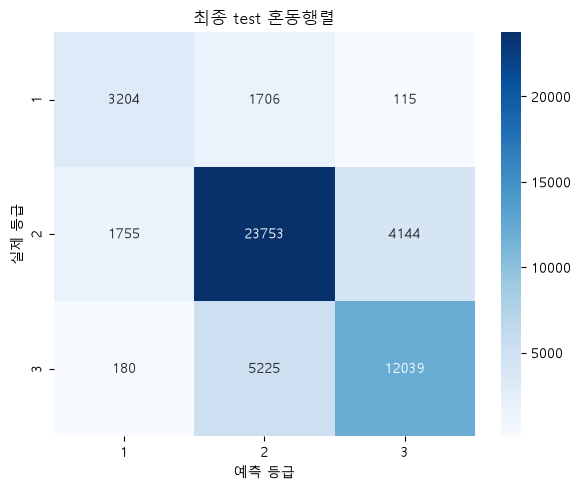

In [19]:
test_predictions = pd.read_csv(
    OUT / "test_predictions.csv"
)

actual = test_predictions["actual"]
predicted = test_predictions["predicted"]


print(
    classification_report(
        actual,
        predicted,
        labels=[1, 2, 3],
        digits=4,
        zero_division=0
    )
)


report_dict = classification_report(
    actual,
    predicted,
    labels=[1, 2, 3],
    output_dict=True,
    zero_division=0
)

report_table = pd.DataFrame({
    name: report_dict[name]
    for name in [
        "1",
        "2",
        "3",
        "macro avg",
        "weighted avg"
    ]
}).T

display(report_table)

save_table(
    report_table.reset_index(names="grade"),
    "test_classification_report"
)


cm = confusion_matrix(
    actual,
    predicted,
    labels=[1, 2, 3]
)

cm_table = pd.DataFrame(
    cm,
    index=[1, 2, 3],
    columns=["pred1", "pred2", "pred3"]
)

save_table(
    cm_table.reset_index(names="actual"),
    "test_confusion_matrix"
)


fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3],
    yticklabels=[1, 2, 3],
    ax=ax
)

ax.set_title("최종 test 혼동행렬")
ax.set_xlabel("예측 등급")
ax.set_ylabel("실제 등급")

plt.tight_layout()

plt.savefig(
    OUT / "test_confusion_matrix.png",
    dpi=160
)

plt.show()

In [20]:
full_top = export_rankings(
    df,
    "full"
)

full_elements = export_elements(
    df,
    "full"
)


# 전체 데이터의 지역별 3등급·2등급 TOP5
for geo in GEO:
    for grade in [3, 2]:
        print(f"\n[전체 데이터 / {geo} / {grade}등급]")

        selected = full_top[
            (full_top["level"] == geo)
            & (full_top["grade"] == grade)
            & (
                full_top["ranking"]
                .isin(["count", "rate_n30"])
            )
        ]

        display(
            selected[
                [
                    "ranking",
                    "region",
                    "n",
                    f"count_{grade}",
                    f"rate_{grade}"
                ]
            ]
        )


# 전체 데이터의 건축 요소별 TOP5
full_element_top5 = pd.read_csv(
    OUT / "full_element_top5.csv"
)

display(
    full_element_top5[
        full_element_top5["grade"].isin([2, 3])
    ][
        [
            "family",
            "grade",
            "ranking",
            "element",
            "value",
            "n",
            "count_2",
            "rate_2",
            "count_3",
            "rate_3"
        ]
    ]
)

print("전체 설명용 표 저장 완료:", OUT)


[전체 데이터 / geo_level_1_id / 3등급]


,ranking,region,n,count_3,rate_3
40,count,17,21813,17615,0.807546
41,count,8,19080,9913,0.519549
42,count,10,22079,8761,0.396802
43,count,21,14889,8710,0.584996
44,count,7,18994,6688,0.352111
50,rate_n30,17,21813,17615,0.807546
51,rate_n30,18,3189,2331,0.730950
52,rate_n30,21,14889,8710,0.584996
53,rate_n30,8,19080,9913,0.519549
54,rate_n30,27,12532,6060,0.483562



[전체 데이터 / geo_level_1_id / 2등급]


,ranking,region,n,count_2,rate_2
20,count,6,24381,16222,0.665354
21,count,26,22615,12645,0.559142
22,count,10,22079,12107,0.548349
23,count,20,17216,11860,0.688894
24,count,7,18994,11273,0.593503
30,rate_n30,29,396,349,0.881313
31,rate_n30,30,2686,2127,0.791884
32,rate_n30,25,5624,4384,0.779516
33,rate_n30,0,4011,3075,0.766642
34,rate_n30,4,14568,11164,0.766337



[전체 데이터 / geo_level_2_id / 3등급]


...

,ranking,region,n,count_3,rate_3
160,count,8236,303,158,0.521452
161,count,2386,209,125,0.598086
162,count,4391,143,120,0.839161
163,count,5957,120,117,0.975000
164,count,1743,117,115,0.982906
170,rate_n30,9880,83,83,1.000000
171,rate_n30,1408,82,82,1.000000
172,rate_n30,3953,60,60,1.000000
173,rate_n30,5807,60,60,1.000000
174,rate_n30,9540,59,59,1.000000



[전체 데이터 / geo_level_3_id / 2등급]


,ranking,region,n,count_2,rate_2
140,count,621,530,343,0.647170
141,count,633,651,273,0.419355
142,count,9229,381,250,0.656168
143,count,2005,466,230,0.493562
144,count,406,251,223,0.888446
150,rate_n30,4354,47,47,1.000000
151,rate_n30,9575,39,39,1.000000
152,rate_n30,7452,35,35,1.000000
153,rate_n30,3851,33,33,1.000000
154,rate_n30,4054,32,32,1.000000


,family,grade,ranking,element,value,n,count_2,rate_2,count_3,rate_3
10,material,2,count,has_superstructure_mud_mortar_stone,1,198561,113947,0.573864,75854,0.382019
11,material,2,count,has_superstructure_timber,1,66450,40187,0.604771,18621,0.280226
12,material,2,count,has_superstructure_bamboo,1,22154,14001,0.631985,5314,0.239866
13,material,2,count,has_superstructure_adobe_mud,1,23101,13902,0.601792,8605,0.372495
14,material,2,count,has_superstructure_mud_mortar_brick,1,17761,11698,0.658634,5440,0.306289
15,material,2,rate,has_superstructure_cement_mortar_stone,1,4752,3248,0.683502,675,0.142045
16,material,2,rate,has_superstructure_mud_mortar_brick,1,17761,11698,0.658634,5440,0.306289
17,material,2,rate,has_superstructure_bamboo,1,22154,14001,0.631985,5314,0.239866
18,material,2,rate,has_superstructure_timber,1,66450,40187,0.604771,18621,0.280226
19,material,2,rate,has_superstructure_adobe_mud,1,23101,13902,0.601792,8605,0.372495


전체 설명용 표 저장 완료: c:\t_project_1_1\nepal_results


In [21]:
# 분할 ID 확인
saved_split = pd.read_csv(
    OUT / "split_ids.csv"
)

assert saved_split["building_id"].is_unique

assert set(saved_split["building_id"]) == set(
    df["building_id"]
)


# test 예측 ID가 원래 남겨 둔 test와 같은지 확인
saved_test = pd.read_csv(
    OUT / "test_predictions.csv"
)

reserved_test_ids = set(
    saved_split.loc[
        saved_split["split"] == "test",
        "building_id"
    ]
)

assert set(saved_test["building_id"]) == reserved_test_ids

assert set(
    saved_test["predicted"].unique()
) <= {1, 2, 3}


# 저장된 예측으로 계산한 점수가 저장 점수와 같은지 확인
recomputed_f1 = f1_score(
    saved_test["actual"],
    saved_test["predicted"],
    average="macro"
)

assert np.isclose(
    recomputed_f1,
    final["macro_f1"]
)


# 지역별 건수와 비율 확인
for prefix, expected_count in [
    ("train", len(train_idx)),
    ("full", len(df))
]:
    for geo in GEO:
        table = pd.read_csv(
            OUT / f"{prefix}_{geo}_all_grades.csv"
        )

        assert table["n"].sum() == expected_count

        assert (
            table[
                ["count_1", "count_2", "count_3"]
            ].sum(axis=1)
            == table["n"]
        ).all()

        assert np.allclose(
            table[
                ["rate_1", "rate_2", "rate_3"]
            ].sum(axis=1),
            1
        )


# 각 CV 후보가 3개 fold를 가졌는지 확인
saved_cv = pd.read_csv(
    OUT / "cv_folds.csv"
)

assert (
    saved_cv.groupby("name")
    .size()
    .eq(3)
    .all()
)

print("분할·예측·점수·지역 집계·CV 검사를 통과했습니다.")

분할·예측·점수·지역 집계·CV 검사를 통과했습니다.


In [23]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

# 앞에서 결과를 저장한 폴더
OUT = Path(OUT)

# 1. 필요한 결과 파일 확인
required_files = [
    "validation_comparison.csv",
    "cv_summary.csv",
    "final_test.json",
    "group_diagnostic.json"
]

for filename in required_files:
    if not (OUT / filename).exists():
        raise FileNotFoundError(
            f"결과 파일이 없습니다: {OUT / filename}\n"
            "OUT 경로와 해당 단계의 실행 완료 여부를 확인하세요."
        )

# 2. 저장된 결과 불러오기
validation = pd.read_csv(OUT / "validation_comparison.csv")
cv_summary = pd.read_csv(OUT / "cv_summary.csv")

with open(OUT / "final_test.json", encoding="utf-8") as f:
    final = json.load(f)

with open(OUT / "group_diagnostic.json", encoding="utf-8") as f:
    group_result = json.load(f)

# 실제 최종 평가에 사용된 설정
winner = final["selected"]

# 3. 기본 LightGBM 점수 찾기
baseline_row = validation.loc[
    validation["name"] == "LGBM_raw",
    "macro_f1"
]

if baseline_row.empty:
    raise ValueError(
        "validation 결과에 LGBM_raw가 없습니다.\n"
        f"저장된 모델 이름: {validation['name'].tolist()}"
    )

baseline_macro_f1 = float(baseline_row.iloc[0])

# 4. 최종 선택 모델의 CV 점수 찾기
# 첫 번째 행이라고 가정하지 않고 모델 이름으로 찾습니다.
selected_cv_row = cv_summary.loc[
    cv_summary["name"] == winner["name"],
    "mean"
]

if selected_cv_row.empty:
    raise ValueError(
        f"CV 결과에 최종 선택 모델 {winner['name']}이 없습니다.\n"
        "서로 다른 실행의 결과 파일이 섞였는지 확인하세요."
    )

best_cv_macro_f1 = float(selected_cv_row.iloc[0])

# 5. 최종 결과표 만들기
result_summary = pd.DataFrame({
    "평가": [
        "기본 LightGBM validation Macro F1",
        "선택 모델 3-fold CV Macro F1",
        "최종 내부 test Macro F1",
        "최종 test Micro F1·정확도",
        "미관측 중지역 진단 Macro F1"
    ],
    "점수": [
        baseline_macro_f1,
        best_cv_macro_f1,
        float(final["macro_f1"]),
        float(final["micro_f1"]),
        float(group_result["macro_f1"])
    ]
})

# Styler 없이 표시하여 추가 의존성 문제도 피합니다.
display(result_summary.round({"점수": 5}))

# 6. 결과 저장
# save_table 함수가 없어도 실행됩니다.
result_summary.to_csv(
    OUT / "result_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("선택된 최종 설정:")
print(json.dumps(winner, ensure_ascii=False, indent=2))

print("\n결과 저장 폴더:")
print(OUT.resolve())

,평가,점수
0,기본 LightGBM validation Macro F1,0.69858
1,선택 모델 3-fold CV Macro F1,0.70143
2,최종 내부 test Macro F1,0.71047
3,최종 test Micro F1·정확도,0.74818
4,미관측 중지역 진단 Macro F1,0.54926


선택된 최종 설정:
{
  "name": "LGBM_tuned_1",
  "kind": "lgbm",
  "features": "raw",
  "method": "grade3",
  "params": {
    "n_estimators": 400,
    "num_leaves": 31,
    "learning_rate": 0.05,
    "min_child_samples": 30,
    "reg_lambda": 1.0
  }
}

결과 저장 폴더:
C:\t_project_1_1\nepal_results


참고로 features="raw"는 원본 입력 변수 38개를 사용했다는 뜻이고, method="grade3"의 실제 가중치는 1등급 1.5 / 2등급 1.0 / 3등급 1.2입니다.